# ODR task with w0 gating: six networks, 500 ms cue (Section IV-A, Fig. 3)

Ring network of 1024 bistable E neurons and 256 LIF I neurons with Mexican-hat E → E weights, after Compte et al. (2000); the differences from their setup are listed in `METHODS_original_vs_ours.md`. Every cue lasts **500 ms**.

**Definitions.** w0 = −1 inside the receptive field (RF) and during every forget window, in every network.
- **RF**: during each hold, w0 = −1 inside the RF (±42.5° around the network's own decoded activity during the cue) and w0_out (0 or +1) outside it. "No RF" = w0 = −1 everywhere, always.
- **pulse**: a negative input current to every E neuron before every cue: −2 for 100 ms before cue 1, −3 for 200 ms in each forget window. Without a pulse there is no forget signal.

| network | hold | before each cue |
|---|---|---|
| no RF, no pulse | w0 = −1 everywhere | nothing |
| no RF, pulse | w0 = −1 everywhere | pulse |
| RF out 0, no pulse | RF, w0_out = 0 | nothing |
| RF out 0, pulse | RF, w0_out = 0 | pulse |
| RF out +1, no pulse | RF, w0_out = +1 | nothing |
| RF out +1, pulse | RF, w0_out = +1 | pulse |

Coding cost (memories 2–10): **active at readout** = share of E neurons that fire at least once in the 400 ms readout; **spikes on the cue** = share of readout spikes from neurons within ±42.5° of the cue (24% = chance); **rate, hold / trial** = mean E rate per neuron from cue offset to readout end / over the whole trial.

Rasters: hatched purple = negative pulse. In each readout window, blue = true cue, red dashed = decoded angle.

**I neurons.** The 256 I neurons are the MNIST / N-MNIST LIF: v ← 0.5·v + I, a spike when v > 1, then v = 0, no synaptic filter. Every LIF in the project is now this neuron; the bistable E neurons are unchanged.
- This LIF is much leakier than the earlier one (LIF_syn: τ_mem 10 ms, τ_syn 5 ms). With the old weights the I neurons never fire.
- So one factor, **14**, multiplies every synapse onto an I neuron (E → I, I → I, background → I). Rule: the I population fires as many spikes over the trial as before (RF out 0 + pulse: 5.0 vs 5.3 Hz). Nothing else changes.
- `X.I_MODEL = "lif_syn"` in the setup cell switches back to that earlier LIF (its results are not included here).

Results: `results/w0_gating_cue500_mnistLIF/`. Sections 2 and 3 load the CSVs there if they exist (set `RERUN = True` to run them again, about 15 min on a laptop CPU).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import w0_gating as g
import w0_experiments as X

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

X.I_MODEL = "lif"        # I neurons: "lif" = MNIST / N-MNIST LIF; "lif_syn" = the earlier LIF (old results)
OUT = "results/w0_gating_cue500_mnistLIF" if X.I_MODEL == "lif" else "results/w0_gating_cue500"
os.makedirs(OUT, exist_ok=True)
RERUN = False            # True: run again even if the CSV exists
GAP = 500                # ms pause after every readout and every forget window
CASES = X.CUE500_CASES   # defined in w0_experiments.py (500 ms cue, 200 ms forget windows)

def cached(name, fn):
    path = os.path.join(OUT, name)
    if os.path.exists(path) and not RERUN:
        print("loaded", path)
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    print("saved", path, f"({len(df)} rows)")
    return df

## 1. Rasters

Cue 1 = 90°, distractor 1 = 210°, cue 2 = 270°, distractor 2 = 30°. One trial shown; the printed errors are medians over 8 trials. In each readout window: blue = true cue, red dashed = decoded angle, arrow = the error.

no RF, no pulse:  memory 1 median error 12.3 deg, memory 2 38.9 deg


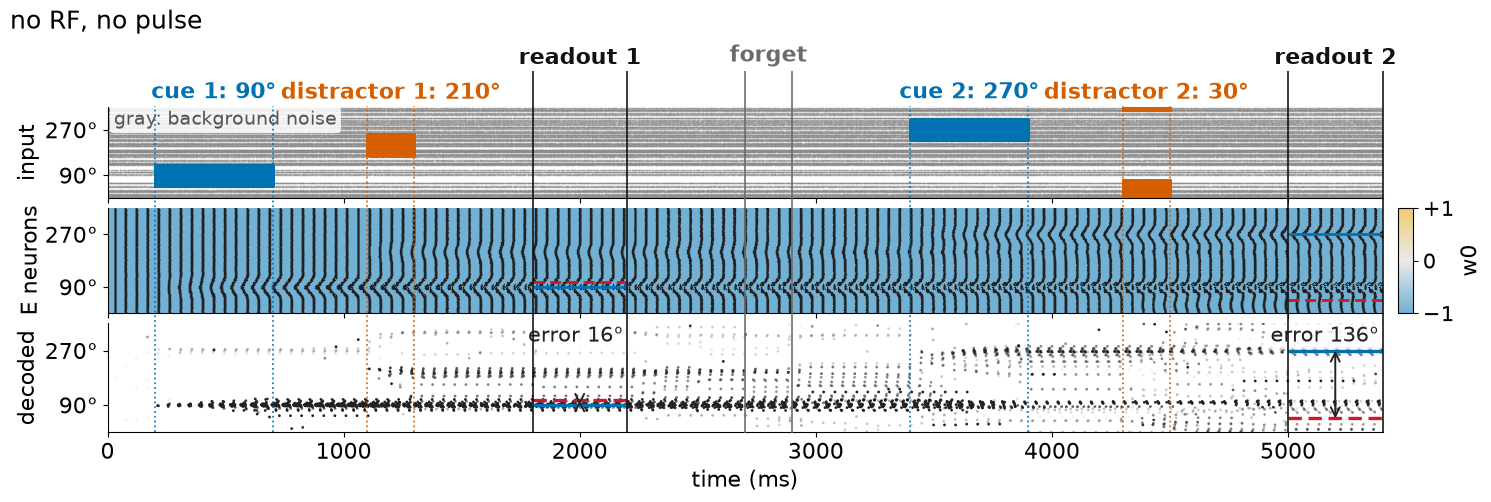

no RF, pulse:  memory 1 median error 12.3 deg, memory 2 77.5 deg


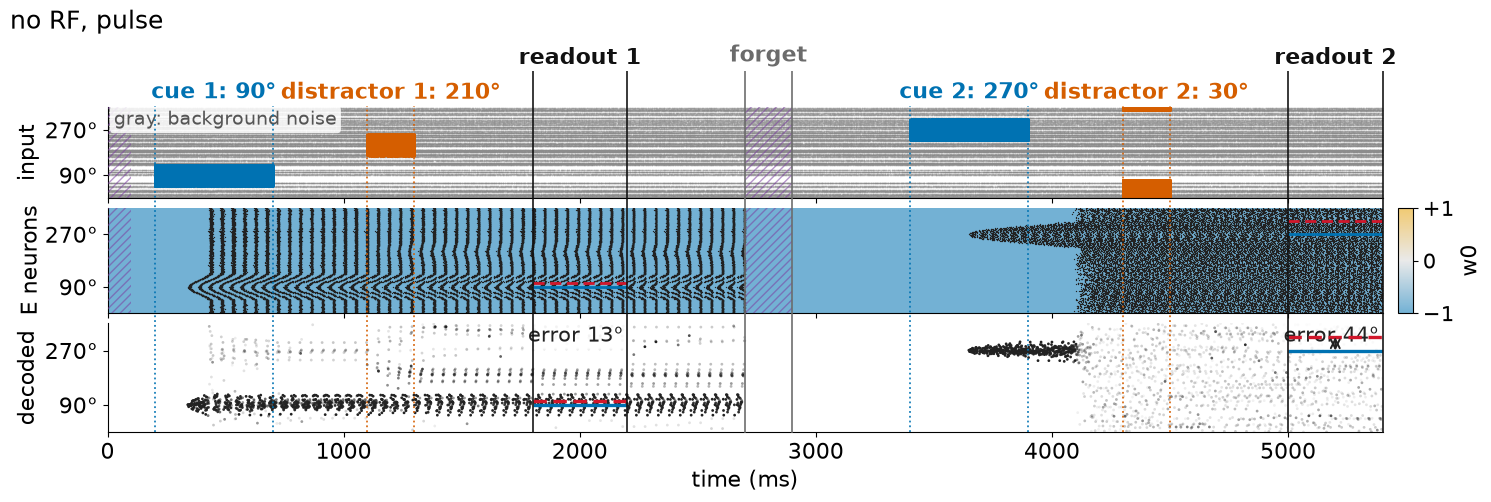

RF out 0, no pulse:  memory 1 median error 3.2 deg, memory 2 156.4 deg


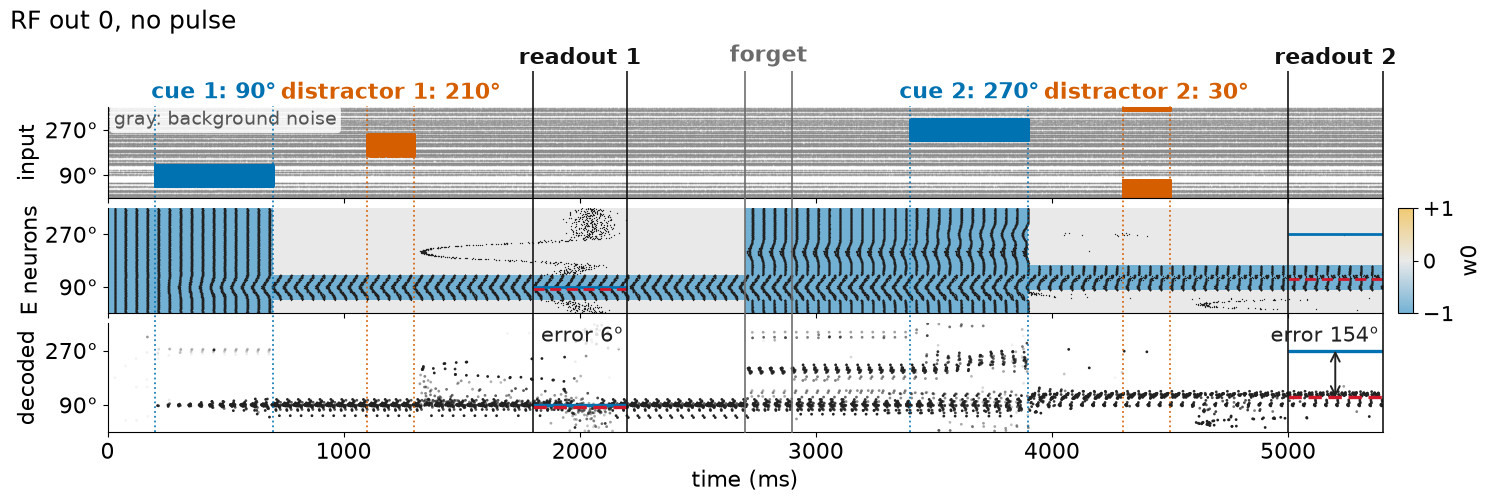

RF out 0, pulse:  memory 1 median error 1.5 deg, memory 2 1.2 deg


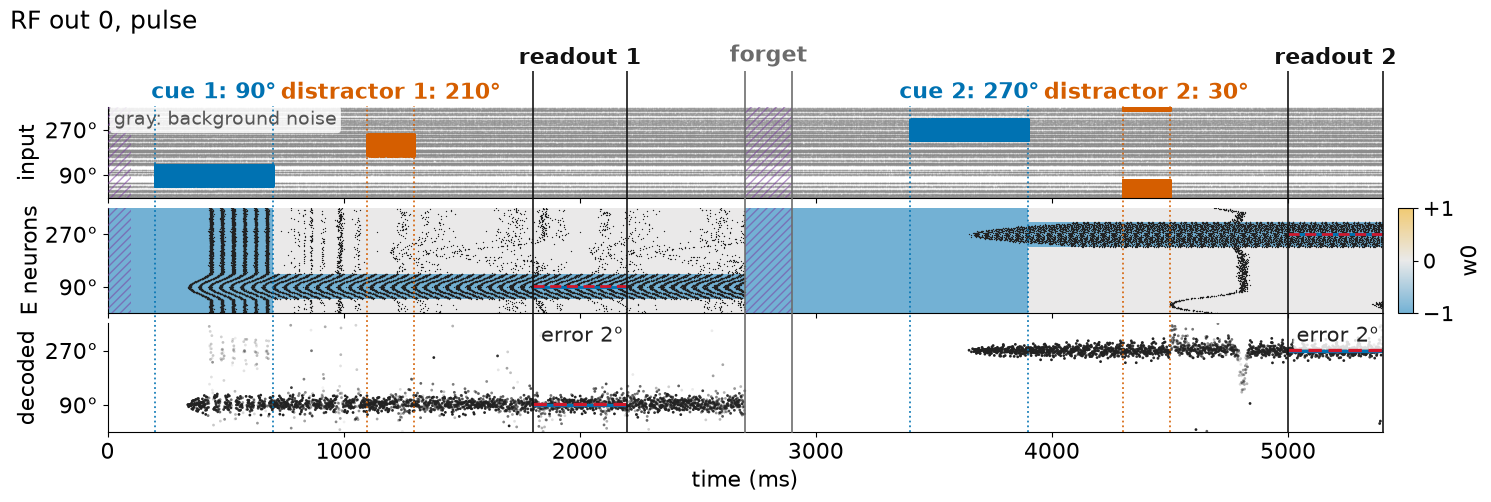

RF out +1, no pulse:  memory 1 median error 2.3 deg, memory 2 162.1 deg


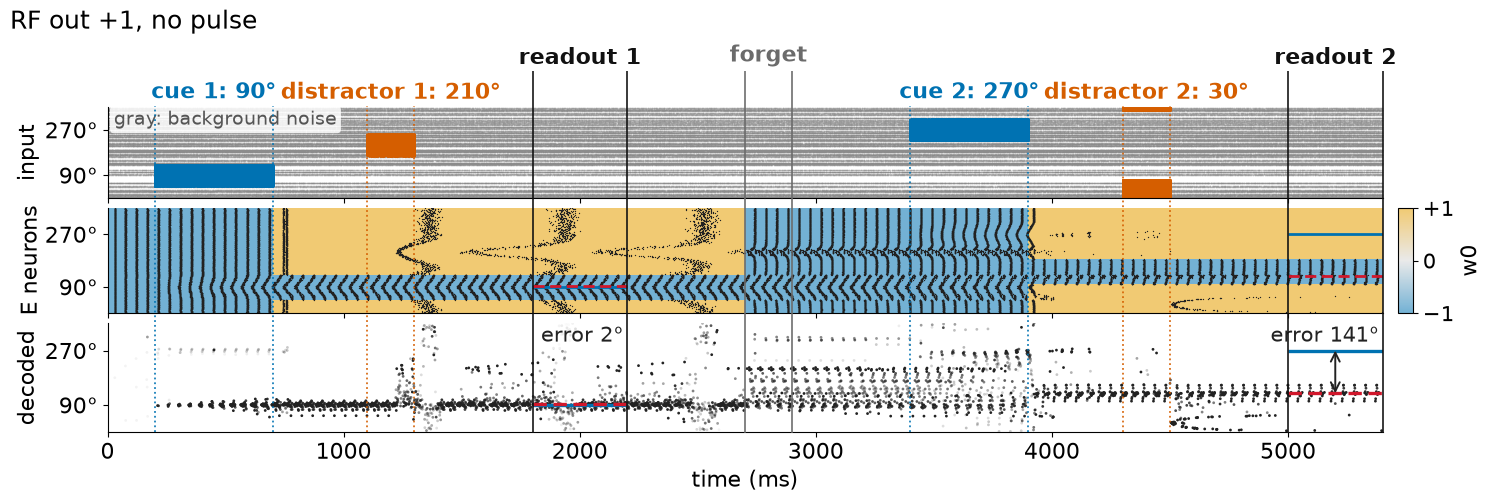

RF out +1, pulse:  memory 1 median error 3.6 deg, memory 2 2.6 deg


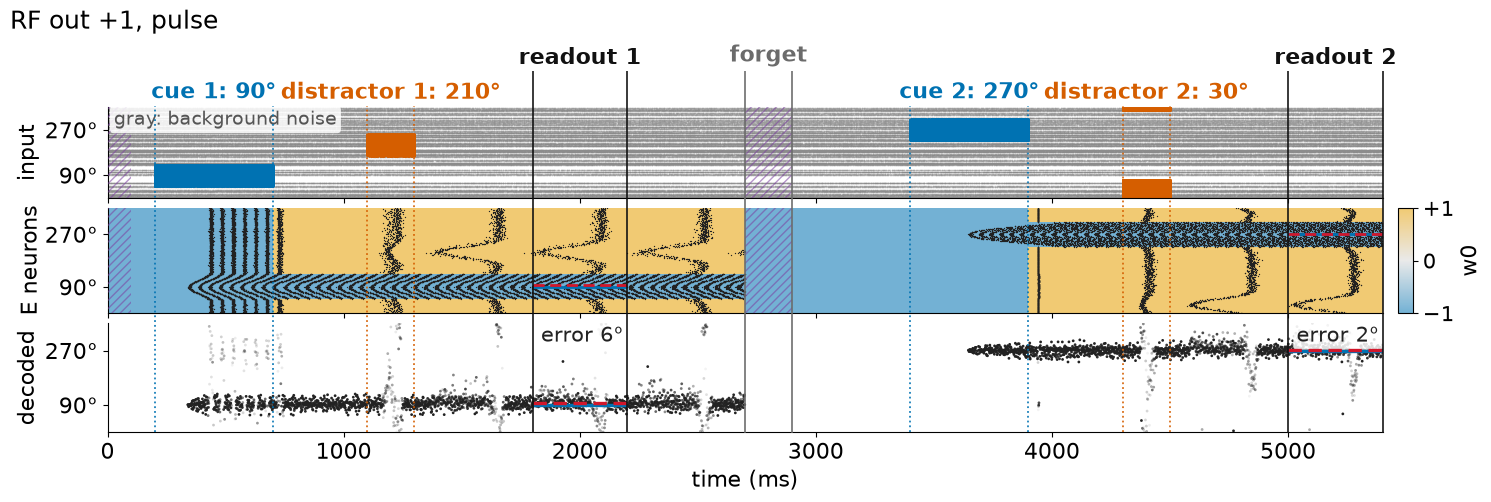

In [2]:
for name, kw in CASES.items():
    pipe, r, df = X.run_sequence((90.0, 270.0), (210.0, 30.0), 8, record=True, gap=GAP, **kw)
    print(f"{name}:  memory 1 median error {df[df.memory == 1].error_deg.median():.1f} deg, "
          f"memory 2 {df[df.memory == 2].error_deg.median():.1f} deg")
    g.plot_pipeline(r, pipe, title=name)
    plt.show()
    del r

## 2. Distractor immunity

Memory 1 only: it comes before any forgetting, so it depends only on the hold and the start pulse. Separation from 180° down to 10°, random cue angles, the distractor on a random side, 2 batches of 8 trials per point (16 trials), the same angles and delay shifts for every case.

One line per network, named in the legend. Colour = w0 outside the RF during the hold (blue: no RF, w0 = −1 everywhere; gray: 0; red: +1). Solid with dots = the network gets the negative pulse before each cue (for memory 1 only the pulse before cue 1 matters); dotted = no pulse. Gray band = the receptive field.

no RF, no pulse                          done in    96 s
no RF, pulse                             done in    99 s
RF out 0, no pulse                       done in    98 s
RF out 0, pulse                          done in    97 s
RF out +1, no pulse                      done in   103 s
RF out +1, pulse                         done in    99 s
saved results/w0_gating_cue500_mnistLIF/cue500_overlap.csv (1728 rows)


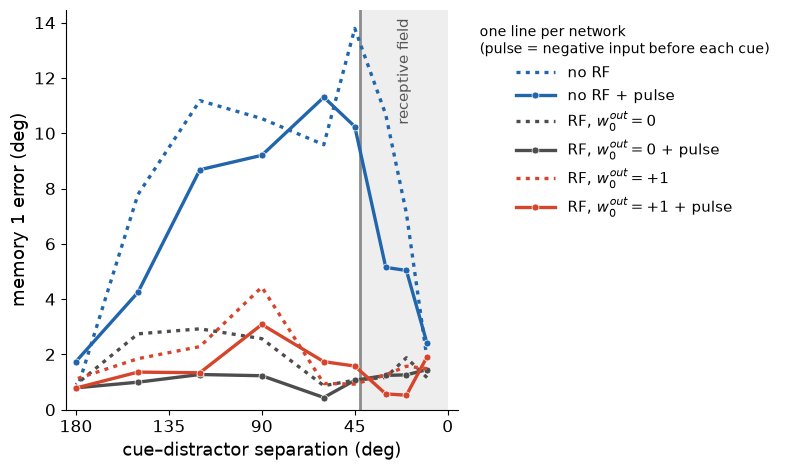

median memory 1 error (deg) by separation:
separation_set_deg   180  150   120   90    60    45    30   20   10 
setup                                                                
no RF, no pulse      0.6  7.8  11.2  10.5   9.6  13.8  10.7  7.1  1.8
no RF, pulse         1.7  4.2   8.7   9.2  11.3  10.2   5.1  5.0  2.4
RF out 0, no pulse   0.9  2.7   2.9   2.6   0.9   1.1   1.2  1.9  1.2
RF out 0, pulse      0.8  1.0   1.3   1.2   0.4   1.1   1.2  1.3  1.5
RF out +1, no pulse  1.1  1.8   2.3   4.4   0.9   0.9   1.3  1.6  1.5
RF out +1, pulse     0.8  1.4   1.3   3.1   1.7   1.6   0.6  0.5  1.9


In [3]:
SEP_CASES = CASES
overlap = cached("cue500_overlap.csv", lambda: X.overlap_sweep(SEP_CASES, n_batches=2, n_trials=8, gap=GAP))
fig, ax = plt.subplots(figsize=(8, 4.8))
X.plot_separation_final(overlap, ax=ax)
fig.tight_layout(); plt.show()
tab = overlap[overlap.memory == 1].groupby(["setup", "separation_set_deg"]).error_deg.median().unstack()
print("median memory 1 error (deg) by separation:")
print(tab[sorted(tab.columns, reverse=True)].reindex(list(SEP_CASES)).round(1).to_string())

## 3. Ten memories in a row: error and coding cost

Ten cue → distractor → readout → forget loops in one trial (about 29 s), 2 batches of 8 trials per case. Each loop has a random cue, a distractor 90 to 180° away and a random extra delay of 0 to 100 ms. Memory 1 is left out of the table; it only tests encoding.

"RF misplaced" = how often the self-placed RF misses the new cue by more than its half-width. It happens when the old memory survives.

no RF, no pulse                          done in    65 s
no RF, pulse                             done in    64 s
RF out 0, no pulse                       done in    65 s
RF out 0, pulse                          done in    62 s
RF out +1, no pulse                      done in    65 s
RF out +1, pulse                         done in    64 s
saved results/w0_gating_cue500_mnistLIF/cue500_repeats.csv (960 rows)
memories 2-10
                     error median (deg)  error mean (deg)  active at readout (%)  readout spikes on the cue (%)  rate readout (Hz)  rate hold (Hz)  rate whole trial (Hz)  RF misplaced (%)
case                                                                                                                                                                                       
no RF, no pulse                    28.9              42.4                  100.0                           23.6               21.3            21.3                   21.3               NaN
no RF, pul

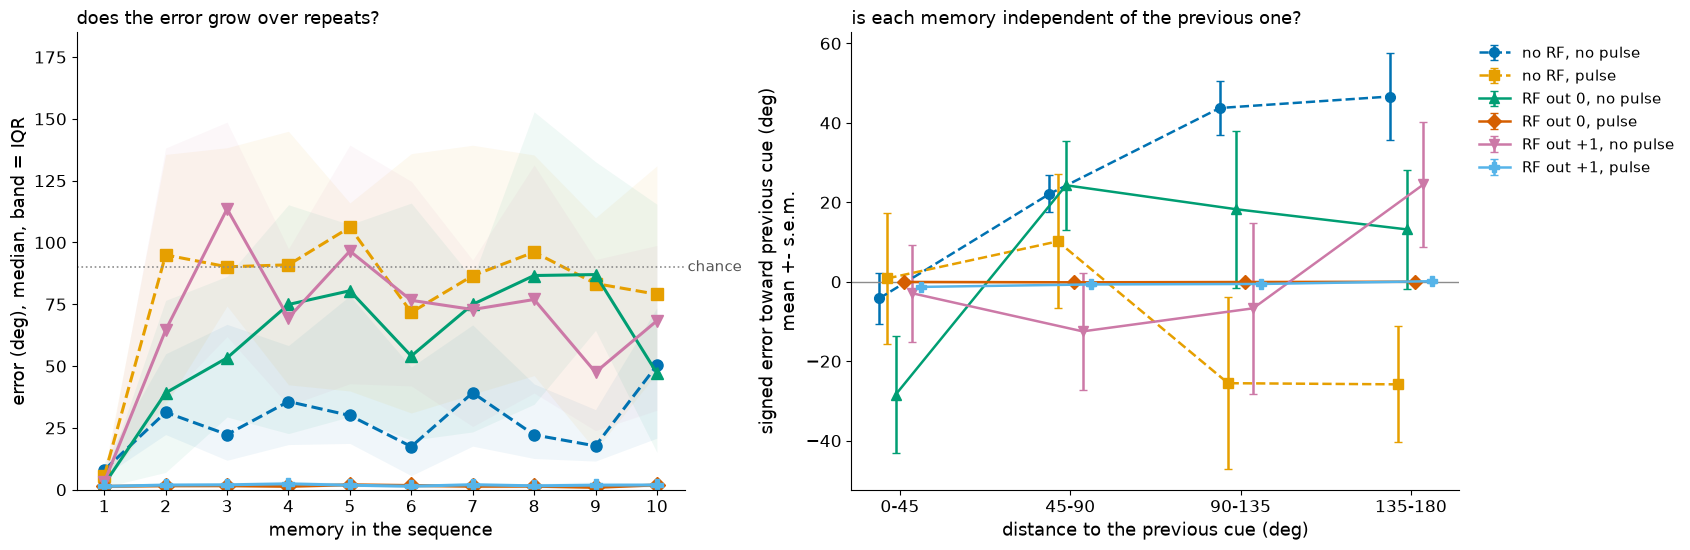

In [4]:
reps = cached("cue500_repeats.csv", lambda: X.repeat_sweep(CASES, n_loops=10, n_batches=2, n_trials=8, gap=GAP))
eff = X.efficiency_table(reps)
print("memories 2-10")
print(eff.round(1).to_string())
X.plot_repeats(reps); plt.show()

### Error against the firing outside the cue region

Mean ± SD error of memories 2–10 against the E rate of neurons farther than 42.5° from the cue during the readout (computed from the readout rate and the share of spikes on the cue). Colour = w0 outside the RF, filled = pulse, open = no pulse, diamond = w0 = +1 during the pulse.

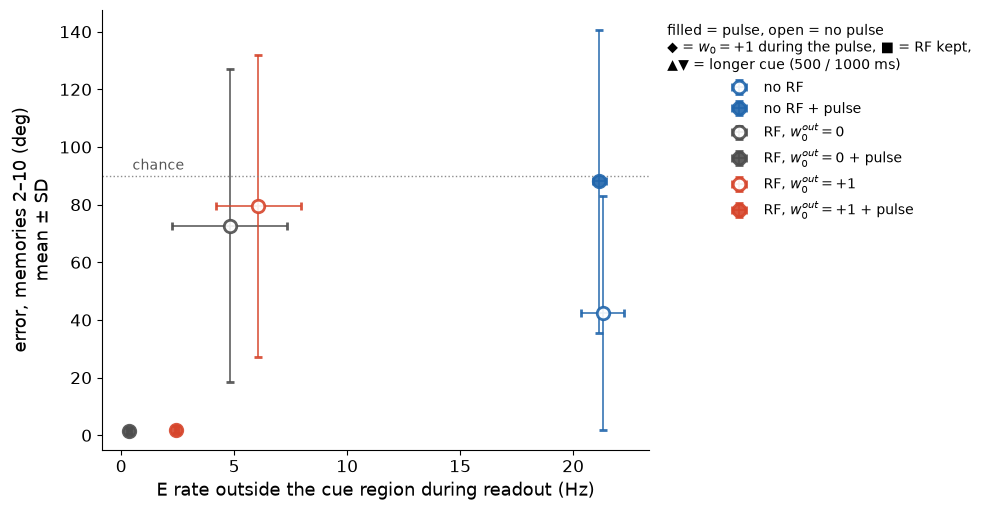

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
X.error_vs_rate_outside(reps, ax=ax)
fig.tight_layout(); plt.show()

### LaTeX table

Error = median over memories 2–10. Needs `\\usepackage{booktabs}`. Also saved to `table_cue500.tex` in the results folder.

In [6]:
print(X.efficiency_latex(reps, path=os.path.join(OUT, "table_cue500.tex")))

\begin{tabular}{lccccc}
\toprule
Network & Error & Active at & Spikes on & Rate, & Rate, \\
 & (deg) & readout (\%) & the cue (\%) & hold (Hz) & trial (Hz) \\
\midrule
no RF, no pulse & 29 & 100 & 24 & 21.3 & 21.3 \\
no RF, pulse & 90 & 100 & 24 & 18.6 & 12.7 \\
RF ($w_0^{out}=0$), no pulse & 66 & 42 & 35 & 5.9 & 11.5 \\
RF ($w_0^{out}=0$), pulse & 2 & 33 & 95 & 5.6 & 4.1 \\
RF ($w_0^{out}=+1$), no pulse & 74 & 78 & 27 & 6.7 & 12.0 \\
RF ($w_0^{out}=+1$), pulse & 2 & 97 & 73 & 7.1 & 4.8 \\
\bottomrule
\end{tabular}


## What this shows (Fig. 3 of the paper)

1. **Distractor immunity (memory 1).** Without an RF, a distractor shifts the memory, with errors up to about 7 % of the largest error (180°). With an RF (w0 = −1 inside, w0_out = 0 or +1 outside) the error stays below 2.5 % at every separation.
2. **Ten memories in a row (memories 2–10).** Only the two networks with both an RF and the negative pulse stay accurate (0.9 % and 1.1 % error). Without a pulse the old bump survives and captures the next cue; without an RF activity spreads over the ring.
3. **Spike cost.** These two networks are also the cheapest: 3.4 and 4.4 Hz mean rate over all 1280 neurons per cue presentation, against 14–27 Hz for the others (`exp_loop_rates.py`, `results/w0_gating_cue500_mnistLIF/cue500_repeats_looprates.csv`).

Caveats: one network size (1024 E). 16 trials per point in section 2; in section 3 the 144 memories per network come from 16 trials and are not independent samples.